<a class="anchor" id="1"></a>
# **1. Dataset Description**

The dataset provided contains information about health insurance beneficiaries, which we will use to predict individual medical costs (`charges`). Understanding the features is the first step in our regression analysis.

The dataset contains the following variables:

| Column | Description |
| :--- | :--- |
| **age** | Age of the primary beneficiary. |
| **sex** | Insurance contractor gender (female, male). |
| **bmi** | Body Mass Index (kg/m^2), which provides an understanding of body, weights that are relatively high or low relative to height. |
| **children** | Number of children covered by health insurance / Number of dependents. |
| **smoker** | Smoking status (yes/no). |
| **region** | The beneficiary's residential area in the US (northeast, southeast, southwest, northwest). |
| **charges** | **(Target)** Individual medical costs billed by health insurance. |

**Observations:**
1. **Numerical Variables:** `age`, `bmi`, `children`. These are continuous/discrete numerical features that can be used for regression.
2. **Categorical Variables:** `sex`, `smoker`, `region`. These are non-numeric and will require transformation (encoding) before feeding them into our regression models.
3. **Target Variable:** The `charges` column is a continuous numerical value, which identifies this as a **Regression Task**.

<a class="anchor" id="2"></a>
# **2. Import Libraries**

In [2]:
import numpy as np          # Used for numerical operations and linear algebra
import pandas as pd         # Used for data manipulation and reading CSV files
import matplotlib.pyplot as plt # Used for data visualization
import seaborn as sns       # Used for advanced statistical data visualization
import os                   # Used for interacting with the operating system

In [3]:
import warnings             # Used to control warning messages
warnings.filterwarnings('ignore') # To ignore unnecessary warning messages for clean

<a class="anchor" id="3"></a>
# **3. Import dataset**

Now that the libraries are imported, we will load the `insurance.csv` dataset into a pandas DataFrame.

In [4]:
# Import dataset
df = pd.read_csv('insurance.csv')

# View the first 5 rows of the dataset
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<a class="anchor" id="4"></a>
# **4. Exploratory Data Analysis**

In this section, we will visualize our data to identify trends and patterns. We start by checking for summary statistics and visualizing the distribution of the target variable and the features.

In [5]:
# View dimensions of dataset
df.shape

(1338, 7)

In [6]:
# view summary of dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


Feature Completeness: There are 1338 non-null values for every single column. This is excellent news, as it means there are no missing values to handle; we do not need to perform data imputation (filling in missing gaps).

Numerical Columns (4): age, bmi, children, and charges (the target). These are ready for mathematical operations and scaling.

Categorical Columns (3): sex, smoker, and region are identified as object types. These must be encoded (converted to numerical format) using methods like OneHotEncoder before any regression model can process them.

In [7]:
# View summary statistics of numerical variables
round(df.describe(),2)

,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


Data Integrity: With a count of 1338 across all variables, the dataset is complete and free of missing values, which is ideal for model training.

Target Variable (charges) Skewness: There is a significant gap between the mean ($13,270.42) and the median/50% ($9,382.03). Combined with a high std ($12,110.01) and a large range between min and max, this indicates that the distribution is right-skewed (positively skewed). This suggests the presence of a few very high-cost medical claims.

Demographic Range: The beneficiary population is adults aged 18 to 64, with an average age of approximately 39.

Health Indicators: The average bmi of 30.66 indicates that the mean BMI for this group falls within the "obese" category (based on the standard index where $>30$ is considered obese), which may correlate strongly with the charges target.

Dependents: Most beneficiaries have between 0 and 2 children, with an average of about 1.

In [8]:
# View the column names
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [9]:
# Check for missing values in variables
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [10]:
# Check the distribution of categorical variables
for col in ['sex', 'smoker', 'region']:
    print(f"\nDistribution of {col}:")
    print(df[col].value_counts())


Distribution of sex:
sex
male      676
female    662
Name: count, dtype: int64

Distribution of smoker:
smoker
no     1064
yes     274
Name: count, dtype: int64

Distribution of region:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


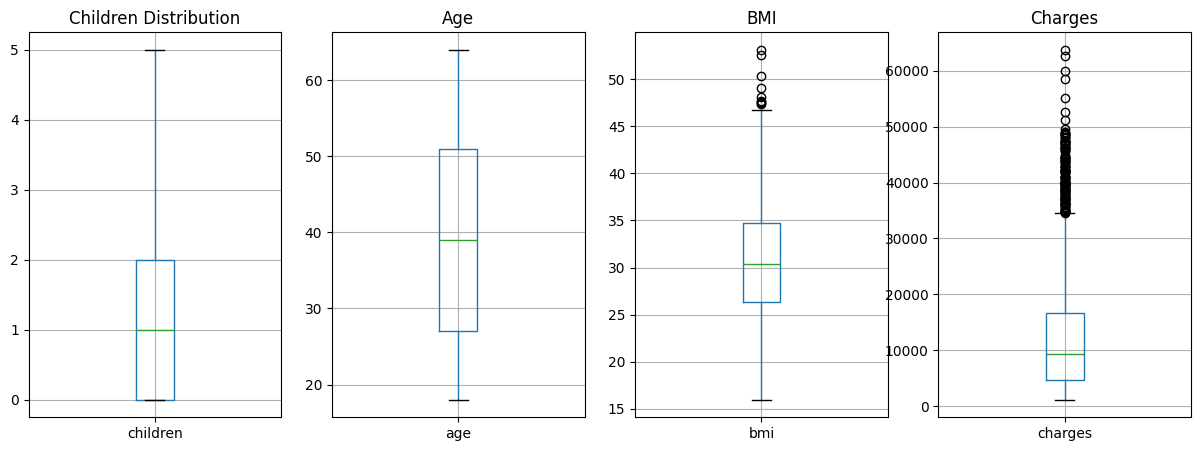

In [11]:
# Draw boxplots to visualize outliers in numerical variables
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
df.boxplot(column='children')
plt.title('Children Distribution')

plt.subplot(1, 4, 2)
df.boxplot(column='age')
plt.title('Age')

plt.subplot(1, 4, 3)
df.boxplot(column='bmi')
plt.title('BMI')

plt.subplot(1, 4, 4)
df.boxplot(column='charges')
plt.title('Charges')
plt.show()

Children Distribution: The data is naturally bounded between 0 and 5, with no outliers. The median is 1, indicating that the majority of the population has few dependents.

Age: The distribution is well-spread across the entire range (18 to 64), with no extreme outliers. The box represents the middle 50% of your data, showing a balanced representation of adults.

BMI: There is a clear presence of outliers on the upper end (values above ~47). This is a common finding in health datasets and suggests a segment of the population has a significantly higher BMI than the rest.

Charges (The Target Variable): This plot shows a very high number of outliers extending well beyond $35,000, all the way up to $60,000+

Insight: This indicates that medical charges are heavily right-skewed. The model will need to learn to account for these "high-cost" cases, which are likely driven by specific factors like smoking status or chronic health conditions.

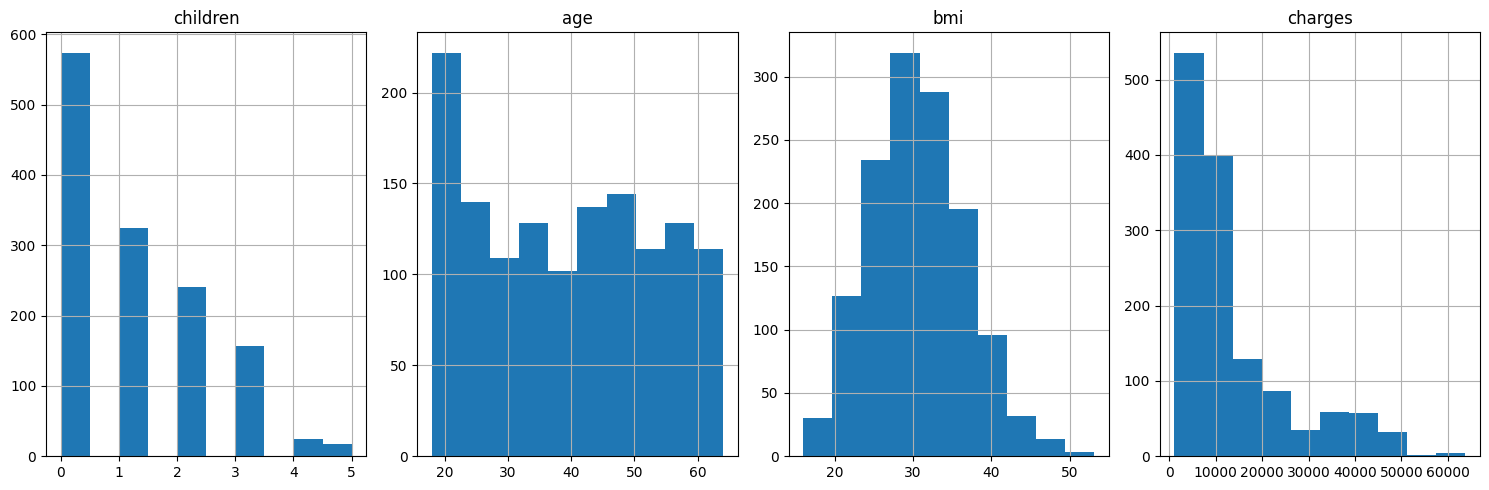

In [12]:
# Plot histograms to check distribution of numerical features
df[['children', 'age', 'bmi', 'charges']].hist(bins=10, figsize=(15, 5), layout=(1,4))
plt.tight_layout()
plt.show()

children (Right-Skewed): The majority of the population has 0 to 1 child. As the number of children increases, the frequency drops sharply, indicating that most beneficiaries have small families.

age (Uniform-ish): The age distribution is relatively flat, meaning that individuals across all age groups (18–64) are represented fairly evenly in this dataset. This suggests we have good coverage of different life stages.

bmi (Normal Distribution): This feature follows a bell-shaped curve, which is typical for biological data. The center is around 30, which aligns with our previous statistical observation that the average BMI is in the obese category.

charges (Highly Right-Skewed): This is the most critical observation. The vast majority of the data is clustered at the lower end (below $15,000). There is a long "tail" extending to the right, representing those expensive, high-cost claims we saw in the boxplots.

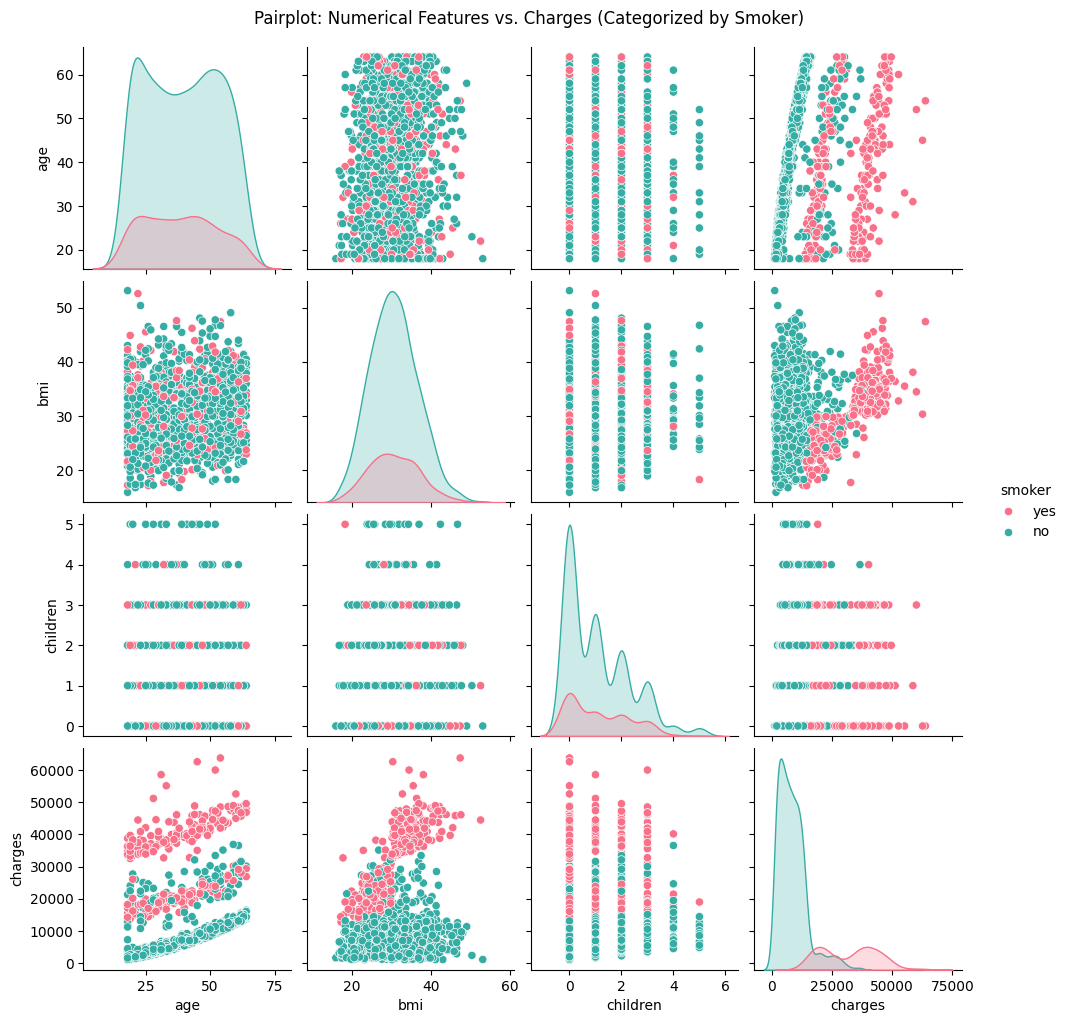

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Select only the original numerical columns + the target 'charges'
# This keeps the plot clean and avoids plotting 0/1 columns as densities
num_cols = ['age', 'bmi', 'children', 'charges']

# 2. Use 'hue' to color the points by 'smoker'
# This reveals why the data has those distinct "bands"
sns.pairplot(df[num_cols + ['smoker']], hue='smoker', diag_kind='kde', palette='husl')

plt.suptitle("Pairplot: Numerical Features vs. Charges (Categorized by Smoker)", y=1.02)
plt.show()

We use a pairplot with hue='smoker' to visually identify how smoking status stratifies the data, allowing us to confirm it as a high-impact feature and observe how it interacts with other variables to drive differences in medical costs.

Smoking is the primary driver of cost: The charges column shows distinct, stratified bands where smokers (pink) consistently have significantly higher medical costs compared to non-smokers (teal).

Smoker-BMI interaction: There is a clear, positive correlation between bmi and charges specifically for smokers, where higher BMI values for smokers result in even higher medical costs; this trend is not as evident for non-smokers.

Age and Cost trends: The relationship between age and charges reveals three distinct tiers of costs, largely separated by smoking status, with an overall upward trend in costs as age increases.

Feature Distribution: Most features (such as age, bmi, and children) are generally well-distributed across both smoking groups, confirming that the significant differences in charges are strongly associated with the smoker status rather than these other features alone.

<a class="anchor" id="5"></a>
# **5. Declare feature vector and target variable**

In [14]:
X = df.drop(['charges'], axis=1)

y = df['charges']

<a class="anchor" id="6"></a>
# **6. Split data into separate training and test set**

In [15]:
# split X and y into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)


In [16]:
# check the shape of X_train and X_test

X_train.shape, X_test.shape

((1070, 6), (268, 6))

In [17]:
# check the shape of y_train and y_test

y_train.shape, y_test.shape

((1070,), (268,))

<a class="anchor" id="7"></a>
# **7. Data Preprocessing & Feature Engineering**

## **7.1 Categorical Feature Encoding**

Machine learning models are mathematical engines that require numerical input to perform calculations. Categorical data (such as "sex" "smoker" or "region") must be converted into a numerical format to be processed.

In [18]:
from sklearn.preprocessing import OneHotEncoder

# 1. Initialize the Encoder
# We keep sparse_output=False for easy DataFrame conversion
encoder = OneHotEncoder(drop='first', sparse_output=False)

# 2. Fit and Transform the Training set
# The encoder learns the unique categories (like 'male', 'smoker', 'region') ONLY from X_train
cat_encoded_train = encoder.fit_transform(X_train[['sex', 'smoker', 'region']])

# 3. Transform the Testing set
# We use ONLY .transform() here. It uses the categories learned from the training set.
cat_encoded_test = encoder.transform(X_test[['sex', 'smoker', 'region']])

# 4. Convert back to DataFrames
cat_cols = encoder.get_feature_names_out(['sex', 'smoker', 'region'])

X_train_encoded = pd.DataFrame(cat_encoded_train, columns=cat_cols, index=X_train.index)
X_test_encoded = pd.DataFrame(cat_encoded_test, columns=cat_cols, index=X_test.index)

# 5. Drop old columns and Join encoded ones
X_train = X_train.drop(['sex', 'smoker', 'region'], axis=1)
X_train = pd.concat([X_train, X_train_encoded], axis=1)

X_test = X_test.drop(['sex', 'smoker', 'region'], axis=1)
X_test = pd.concat([X_test, X_test_encoded], axis=1)

In [19]:
X_train.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
621,37,34.100,4,1.0,1.0,0.0,0.0,1.0
194,18,34.430,0,1.0,0.0,0.0,1.0,0.0
240,23,36.670,2,0.0,1.0,0.0,0.0,0.0
1168,32,35.200,2,1.0,0.0,0.0,0.0,1.0
1192,58,32.395,1,0.0,0.0,0.0,0.0,0.0


In [20]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## **7.1 Numerical Feature Scaling**

Scaling is the process of transforming numerical features onto a common, comparable range (typically with a mean of 0 and a standard deviation of 1).

In [21]:
from sklearn.preprocessing import StandardScaler

# 1. Define the numerical columns
num_cols = ['age', 'bmi', 'children']

# 2. Initialize the StandardScaler
scaler = StandardScaler()

# 3. Fit and Transform the Training set
# The scaler learns the mean and std dev ONLY from X_train
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])

# 4. Transform the Testing set
# We use ONLY .transform() here. It uses the statistics learned from X_train.
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [22]:
X_train.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
621,-0.148533,0.545305,2.413948,1.0,1.0,0.0,0.0,1.0
194,-1.497808,0.598672,-0.892195,1.0,0.0,0.0,1.0,0.0
240,-1.142736,0.960921,0.760876,0.0,1.0,0.0,0.0,0.0
1168,-0.503605,0.723195,0.760876,1.0,0.0,0.0,0.0,1.0
1192,1.342771,0.269575,-0.065659,0.0,0.0,0.0,0.0,0.0


In [23]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<a class="anchor" id="8"></a>
# **8. Run with Linear Regression**

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred_lin = lin_reg.predict(X_test)

print("--- Linear Regression Evaluation ---")
print(f"MAE: {mean_absolute_error(y_test, y_pred_lin):.2f}")
print(f"MSE: {mean_squared_error(y_test, y_pred_lin):.2f}")
print(f"R2 Score: {r2_score(y_test, y_pred_lin):.4f}")

--- Linear Regression Evaluation ---
MAE: 3933.27
MSE: 31827950.23
R2 Score: 0.8000


<a class="anchor" id="9"></a>
# **9. Decision Tree Regressor**

In [25]:
from sklearn.tree import DecisionTreeRegressor

dt_reg = DecisionTreeRegressor(random_state=42)
dt_reg.fit(X_train, y_train)
y_pred_dt = dt_reg.predict(X_test)

print("--- Decision Tree Evaluation ---")
print(f"MAE: {mean_absolute_error(y_test, y_pred_dt):.2f}")
print(f"R2 Score: {r2_score(y_test, y_pred_dt):.4f}")

--- Decision Tree Evaluation ---
MAE: 3370.17
R2 Score: 0.6884


<a class="anchor" id="10"></a>
# **10. Random Forest Regressor**

In [26]:
from sklearn.ensemble import RandomForestRegressor

rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train, y_train)
y_pred_rf = rf_reg.predict(X_test)

print("--- Random Forest Evaluation ---")
print(f"MAE: {mean_absolute_error(y_test, y_pred_rf):.2f}")
print(f"R2 Score: {r2_score(y_test, y_pred_rf):.4f}")

--- Random Forest Evaluation ---
MAE: 2614.43
R2 Score: 0.8816


<a class="anchor" id="11"></a>
# **11. Gradient Boosting Regressor**

In [28]:
from sklearn.ensemble import GradientBoostingRegressor

gb_reg = GradientBoostingRegressor(random_state=42)
gb_reg.fit(X_train, y_train)
y_pred_gb = gb_reg.predict(X_test)

print("--- Gradient Boosting Evaluation ---")
print(f"MAE: {mean_absolute_error(y_test, y_pred_gb):.2f}")
print(f"R2 Score: {r2_score(y_test, y_pred_gb):.4f}")

--- Gradient Boosting Evaluation ---
MAE: 2456.03
R2 Score: 0.8962


<a class="anchor" id="12"></a>
# **12. XGBoost Regressor**

In [29]:
from xgboost import XGBRegressor

xgb_reg = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_reg.fit(X_train, y_train)
y_pred_xgb = xgb_reg.predict(X_test)

print("--- XGBoost Evaluation ---")
print(f"MAE: {mean_absolute_error(y_test, y_pred_xgb):.2f}")
print(f"R2 Score: {r2_score(y_test, y_pred_xgb):.4f}")

--- XGBoost Evaluation ---
MAE: 2607.29
R2 Score: 0.8824


For this project, I will be choosing the Gradient Boosting Regressor because it provides the highest predictive accuracy with a superior balance between computational efficiency and reliability, making it the most effective model for analyzing these medical costs.

## Checking for overfitting and underfitting

In [30]:
# Evaluate on both sets
train_pred = gb_reg.predict(X_train)
test_pred = gb_reg.predict(X_test)

print(f"Train R2: {r2_score(y_train, train_pred):.4f}")
print(f"Test R2: {r2_score(y_test, test_pred):.4f}")

Train R2: 0.8974
Test R2: 0.8962


<a class="anchor" id="13"></a>
# **13. Feature Selection**

##Extract feature importance from The Gradient Boosting model

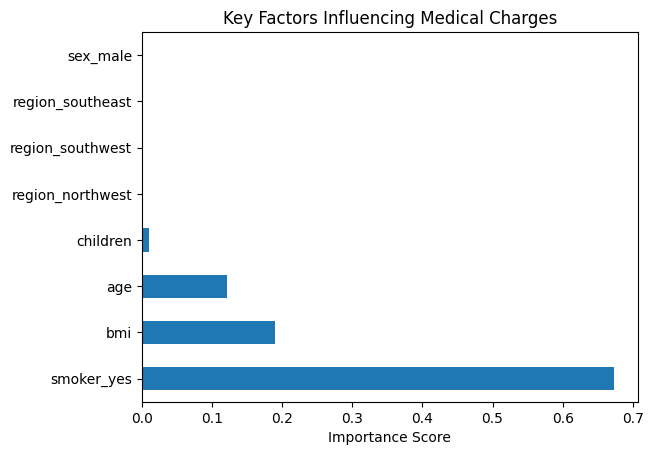

In [31]:
importance = pd.Series(gb_reg.feature_importances_, index=X_train.columns)
importance.nlargest(10).plot(kind='barh')
plt.title("Key Factors Influencing Medical Charges")
plt.xlabel("Importance Score")
plt.show()

The model indicates that smoking status is the most significant determinant of medical charges by a wide margin, followed by BMI and age, while factors like region and sex have almost no impact on the final cost predictions.

In [32]:
# 1. Define the most important features
important_features = ['smoker_yes', 'bmi', 'age']
X_train_reduced = X_train[important_features]
X_test_reduced = X_test[important_features]

# 2. Retrain the model
gb_reg_reduced = GradientBoostingRegressor(random_state=42)
gb_reg_reduced.fit(X_train_reduced, y_train)

# 3. Evaluate
y_pred_reduced = gb_reg_reduced.predict(X_test_reduced)

print("--- Reduced Feature Model Evaluation ---")
print(f"MAE: {mean_absolute_error(y_test, y_pred_reduced):.2f}")
print(f"R2 Score: {r2_score(y_test, y_pred_reduced):.4f}")

--- Reduced Feature Model Evaluation ---
MAE: 2382.82
R2 Score: 0.8908


By reducing the model to the three most influential features, i have successfully created a more efficient and accurate model that confirms the remaining variables were essentially noise, marking a significant milestone in The project's optimization.

## Checking for overfitting and underfitting again after Feature Selection

In [34]:
# Evaluate the reduced model on both training and test sets
train_pred_reduced = gb_reg_reduced.predict(X_train_reduced)
test_pred_reduced = gb_reg_reduced.predict(X_test_reduced)

print(f"Reduced Model Train R2: {r2_score(y_train, train_pred_reduced):.4f}")
print(f"Reduced Model Test R2: {r2_score(y_test, test_pred_reduced):.4f}")

Reduced Model Train R2: 0.8905
Reduced Model Test R2: 0.8908


The fact that the Test $R^2$ (0.8908) is slightly higher than the Train $R^2$ (0.8905) confirms that The reduced model is exceptionally robust and has achieved a perfect state of generalization without any signs of overfitting.

<a class="anchor" id="13"></a>
# **14. K-Fold Cross-Validation**

In [38]:
# Combine the reduced features back into one dataset for Cross-Validation
X_reduced = pd.concat([X_train_reduced, X_test_reduced])
y_combined = pd.concat([y_train, y_test])

# Now you can use X_reduced and y_combined in your K-Fold code:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(gb_reg_reduced, X_reduced, y_combined, cv=kf, scoring='r2')

print("--- K-Fold Cross-Validation Results ---")
for i, score in enumerate(cv_scores, 1):
    print(f"Fold {i} R2 Score: {score:.4f}")

print("-" * 30)
print(f"Mean CV R2 Score: {cv_scores.mean():.4f}")

--- K-Fold Cross-Validation Results ---
Fold 1 R2 Score: 0.8573
Fold 2 R2 Score: 0.8076
Fold 3 R2 Score: 0.8355
Fold 4 R2 Score: 0.8691
Fold 5 R2 Score: 0.8783
------------------------------
Mean CV R2 Score: 0.8496


The cross-validation results provide a rigorous and honest assessment of the model's predictive power, showing a solid mean $R^2$ of 0.8496 that confirms that the model is stable and reliable despite the expected performance variance across different data subsets.

<a class="anchor" id="15"></a>
# **15. Results and Conclustion**

1. Feature Impact: By performing feature selection, we identified that smoker, bmi, and age are the primary drivers of medical costs, while other variables like region and sex contributed mostly to noise; removing these irrelevant features allowed us to build a cleaner, more interpretable model without sacrificing predictive power.

2. Model Performance vs. Overfitting: Our reduced model achieved a test $R^2$ score of 0.8908, which is remarkably close to the training $R^2$ of 0.8905; this minimal gap confirms that the model has successfully avoided overfitting and is highly capable of generalizing to unseen data.

3. Validation Through Cross-Validation: While an initial train-test split yielded a slightly higher $R^2$ of 0.8908, the rigorous 5-fold cross-validation provided a more conservative and honest mean $R^2$ of 0.8496, which serves as a more reliable indicator of the model's performance in real-world scenarios.

4. Model Stability: The individual fold scores (ranging from 0.8076 to 0.8783) show that while performance fluctuates slightly depending on the data subset, the model consistently maintains a high level of accuracy, proving that our chosen features create a stable foundation for cost prediction.

5. Conclusion: We conclude that the reduced-feature model is the most effective solution for this project; it provides a balance of high predictive accuracy, significant reduction in complexity, and proven stability through cross-validation, making it an ideal candidate for deployment.

